# **- 머신러닝(딥러닝) 프로젝트 진행 절차**

### - 라이브러리 임포트
      - 실습에 필요한 라이브러리를 임포트합니다.

In [3]:
# !pip install numpy pandas

import numpy as np
import pandas as pd

# 모든 경고 무시
import warnings
warnings.filterwarnings("ignore")

# skLearn train_test_split의 동일한 결과 출력을 위해
np.random.seed(75)


# 1. 문제 정의
#### - 농구 선수의 경기 기록을 바탕으로, 그 선수의 포지션을 예측해보도록 하겠습니다.


# 2. 데이터 수집

In [4]:
# 데이터를 수집합니다.

df = pd.read_csv("./data/csv/basketball_stat.csv")

# 수집된 데이터 샘플 확인
df.head()

# 영향 있는 요소들 위주로 예측모델에 학습시킴

,Player,Pos,3P,2P,TRB,AST,STL,BLK
0,Alex Abrines,SG,1.4,0.6,1.3,0.6,0.5,0.1
1,Steven Adams,C,0.0,4.7,7.7,1.1,1.1,1.0
2,Alexis Ajinca,C,0.0,2.3,4.5,0.3,0.5,0.6
3,Chris Andersen,C,0.0,0.8,2.6,0.4,0.4,0.6
4,Will Barton,SG,1.5,3.5,4.3,3.4,0.8,0.5


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  100 non-null    str    
 1   Pos     100 non-null    str    
 2   3P      100 non-null    float64
 3   2P      100 non-null    float64
 4   TRB     100 non-null    float64
 5   AST     100 non-null    float64
 6   STL     100 non-null    float64
 7   BLK     100 non-null    float64
dtypes: float64(6), str(2)
memory usage: 6.4 KB


In [6]:
df.describe() # 데이터의 특징

,3P,2P,TRB,AST,STL,BLK
count,100.00000,100.000000,100.000000,100.000000,100.000000,100.00000
mean,1.08200,3.265000,5.030000,1.892000,0.725000,0.69600
std,0.91424,1.843053,3.098599,1.257357,0.343004,0.59661
min,0.00000,0.500000,1.300000,0.200000,0.000000,0.10000
25%,0.00000,1.900000,2.875000,0.975000,0.500000,0.20000
50%,1.30000,2.900000,3.900000,1.500000,0.700000,0.55000
75%,1.80000,4.450000,6.325000,2.600000,0.925000,1.00000
max,3.40000,9.700000,14.100000,5.900000,1.600000,3.00000


In [7]:
# 현재 가지고 있는 데이터에서, 포지션의 갯수를 확인
# 예측 모델 생성 (카테고리)
df.Pos.value_counts()

Pos
SG    50
C     50
Name: count, dtype: int64

# 3. 데이터 시각화(특징 파악)

#### 데이터 특징을 바탕으로 한 공간에 시각화함으로써 우리는 머신러닝,
#### 학습에 필요한 특징과 불필요한 특징을 쉽게 구분지을 수 있다

In [8]:
# pip install seaborn 
import matplotlib.pyplot as plt
import seaborn as sb

Text(0.5, 1.0, 'STL and 2P')

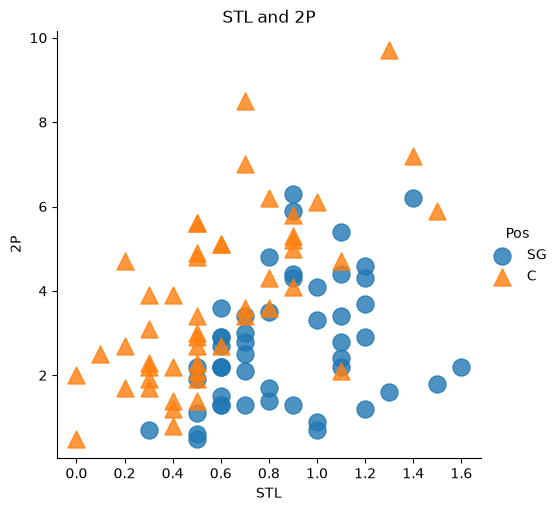

In [9]:
# 'STL(스틸)', '2P(2점슛)' 데이터 시각화
sb.lmplot(data = df, x ='STL', y = '2P', hue = 'Pos'
          , fit_reg = False, scatter_kws ={"s":150}
          , markers=["o", "^"])

# title
plt.title("STL and 2P")

Text(0.5, 1.0, 'AST and 2P')

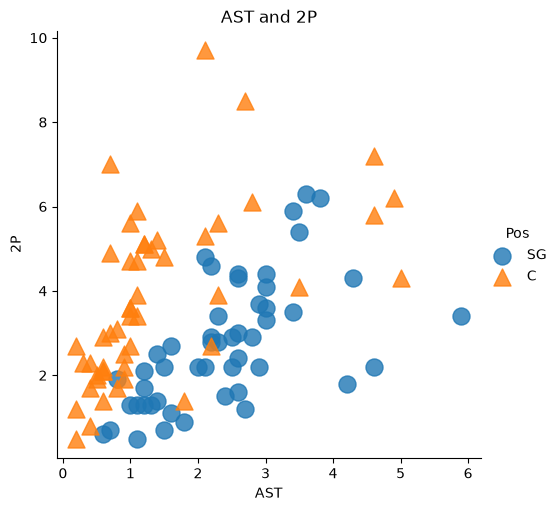

In [10]:
# 'AST(어시스트)', '2P(2점슛)' 데이터 시각화
sb.lmplot(data = df, x ='AST', y = '2P', hue = 'Pos'
          , fit_reg = False, scatter_kws ={"s":150}
          , markers=["o", "^"])

# title
plt.title("AST and 2P")

Text(0.5, 1.0, 'BLK and 3P uin 2d plane')

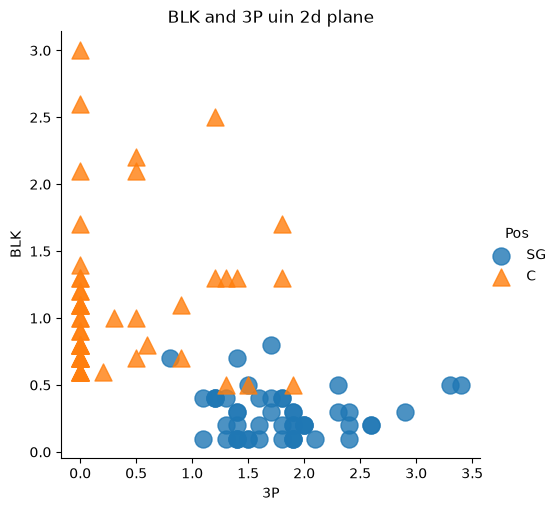

In [11]:
# 'BLK(블로킹)', '3P(2점슛)' 데이터 시각화
sb.lmplot(data = df, x ='3P', y = 'BLK', hue = 'Pos'
          , fit_reg = False, scatter_kws ={"s":150}
          , markers=["o", "^"])

# title
plt.title("BLK and 3P uin 2d plane")

# 결과 : 포지션 SG는 3P 점수가 높음 대신 BLK 점수 낮음 <-> 포지션 C는 BLK 점수가 높음 대신 3P 점수는 낮음

Text(0.5, 1.0, 'TRB and 3P uin 2d plane')

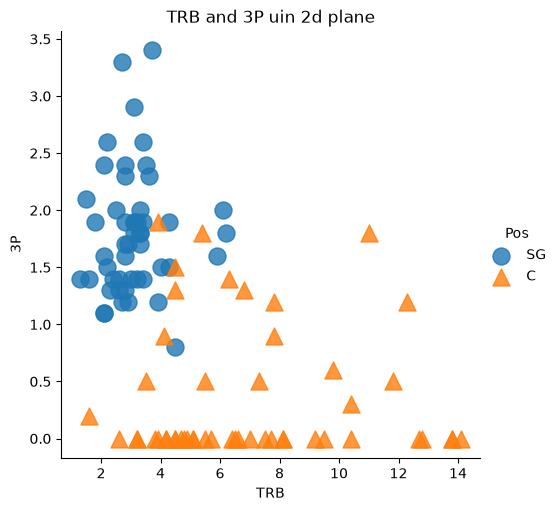

In [12]:
# 'TRB(리바운드)', '3P(2점슛)' 데이터 시각화
sb.lmplot(data = df, x ='TRB', y = '3P', hue = 'Pos'
          , fit_reg = False, scatter_kws ={"s":150}
          , markers=["o", "^"])

# title
plt.title("TRB and 3P uin 2d plane")

# 결과 : 포지션 SG는 3P 점수가 높음 대신 BLK 점수 낮음 <-> 포지션 C는 BLK 점수가 높음 대신 3P 점수는 낮음

# 4. 데이터 전처리(다듬기)

In [13]:
# 분별력이 없는 특징 (FEATURE)을 데이터에서 제거 (y축 제거), 
# 열 drop후 새로운 메모리 시작주소값으로 새로연결 inplace true일 경우 덮어쓰기 
# false 면 따로 관리 따로 변수를 선언해 연결할수밖에 없음 
df.drop(['2P', 'AST', 'STL'], axis = 1, inplace = True)
df.head()

,Player,Pos,3P,TRB,BLK
0,Alex Abrines,SG,1.4,1.3,0.1
1,Steven Adams,C,0.0,7.7,1.0
2,Alexis Ajinca,C,0.0,4.5,0.6
3,Chris Andersen,C,0.0,2.6,0.6
4,Will Barton,SG,1.5,4.3,0.5


# 5. 데이터 나누기 (학습 데이터, 테스트 데이터)

In [14]:
# !pip install sikit-learn

# import sklearn.model_selection as skl

from sklearn.model_selection import train_test_split as tts

# 다듬어진 데이터에서 20% 테스트 데이터 / 80% 학습 데이터 분류
train, test = tts(df, test_size=0.2)

# 학습 데이터의 갯수를 확인
print(train.shape[0])

# 테스트 데이터의 갯수를 확인
print(test.shape[0])

80
20


# 6. 저장 (보관)

In [15]:
train.to_csv("./data/csv/basketball_train.csv", index=None)

train.to_csv("./data/csv/basketball_test.csv", index=None)